In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.signal import resample_poly


In [2]:
from pathlib import Path

In [3]:
def iq_plot(i_signal, q_signal):
    plt.scatter(i_signal, q_signal)
    plt.title("IQ Plot")
    plt.xlabel("I")
    plt.ylabel("Q")
    plt.show()

def plot_power(signal, color="tab:blue", alpha=1.0):
    N = signal.shape[0]
    freq = np.arange(f/-2, f/2, f/N)
    fft_signal = np.fft.fft(signal)
    power_signal = 10*np.log10(np.fft.fftshift(np.absolute(fft_signal)))
    plt.plot(freq, power_signal, color=color, alpha=alpha)
    plt.title("Signal Power [dB]")
    plt.xlabel("freq")
    plt.ylabel("dB")
    #plt.show()

def get_spectogram(x):
    sample_rate = 5e6
    fft_size = 1024
    num_rows = len(x) // fft_size # // is an integer division which rounds down
    spectrogram = np.zeros((num_rows, fft_size))
    for i in range(num_rows):
        spectrogram[i,:] = 10*np.log10(np.abs(np.fft.fftshift(np.fft.fft(x[i*fft_size:(i+1)*fft_size])))**2)

    plt.imshow(spectrogram, aspect='auto', extent = [sample_rate/-2/1e6, sample_rate/2/1e6, 0, len(x)/sample_rate])
    plt.xlabel("Frequency [MHz]")
    plt.ylabel("Time [s]")
    plt.show()


def time_sync(x):
    samples = x # for the sake of matching the sync chapter
    samples_interpolated = resample_poly(samples, 32, 1) # we'll use 32 as the interpolation factor, arbitrarily chosen, seems to work better than 16
    sps = 4
    mu = 0.01 # initial estimate of phase of sample
    out = np.zeros(len(samples) + 10, dtype=np.complex64)
    out_rail = np.zeros(len(samples) + 10, dtype=np.complex64) # stores values, each iteration we need the previous 2 values plus current value
    i_in = 0 # input samples index
    i_out = 2 # output index (let first two outputs be 0)
    while i_out < len(samples) and i_in+32 < len(samples):
        out[i_out] = samples_interpolated[i_in*32 + int(mu*32)] # grab what we think is the "best" sample
        out_rail[i_out] = int(np.real(out[i_out]) > 0) + 1j*int(np.imag(out[i_out]) > 0)
        x = (out_rail[i_out] - out_rail[i_out-2]) * np.conj(out[i_out-1])
        y = (out[i_out] - out[i_out-2]) * np.conj(out_rail[i_out-1])
        mm_val = np.real(y - x)
        mu += sps + 0.01*mm_val
        i_in += int(np.floor(mu)) # round down to nearest int since we are using it as an index
        mu = mu - np.floor(mu) # remove the integer part of mu
        i_out += 1 # increment output index
    x = out[2:i_out] # remove the first two, and anything after i_out (that was never filled out)

    return x


# For QPSK
def phase_detector_4(sample):
    if sample.real > 0:
        a = 1.0
    else:
        a = -1.0
    if sample.imag > 0:
        b = 1.0
    else:
        b = -1.0
    return a * sample.imag - b * sample.real


def fine_freq_sync(x):
    # Fine freq sync
    samples = x # for the sake of matching the sync chapter
    N = len(samples)
    phase = 0
    freq = 0
    # These next two params is what to adjust, to make the feedback loop faster or slower (which impacts stability)
    alpha = 8e10
    beta = 2.2
    out = np.zeros(N, dtype=np.complex64)
    freq_log = []
    for i in range(N):
        out[i] = samples[i] * np.exp(-1j*phase) # adjust the input sample by the inverse of the estimated phase offset
        error = np.real(out[i]) * np.imag(out[i]) # This is the error formula for 2nd order Costas Loop (e.g. for BPSK)
        #error = phase_detector_4(out[i])

        # Advance the loop (recalc phase and freq offset)
        freq += (beta * error)
        freq_log.append(freq * sample_rate / (2*np.pi)) # convert from angular velocity to Hz for logging
        phase += freq + (alpha * error)

        # Optional: Adjust phase so its always between 0 and 2pi, recall that phase wraps around every 2pi
      #   while phase >= 2*np.pi:
      #      phase -= 2*np.pi
      #   while phase < 0:
      #      phase += 2*np.pi
    x = out
    return x, freq_log

# Load Data

In [4]:
PATH = "data"

# Frequency= 2460 MHz
# RF Bandwidth = 25 MHz
FILE = "capture_2460mhz"

# Frequency= 102.5 MHz
# RF Bandwidth = 5 MHz
#FILE = "capture_102_5mhz"

# Frequency= 848 MHz
# RF Bandwidth = 10 MHz
#FILE = "capture_848mhz"

In [5]:
path = Path(PATH)
data = np.loadtxt(path/FILE, skiprows=1)

# Data Conditioning

In [6]:
# Transform data into complex format
rx = data[:,0] + data[:,1]*1j

# Create IQ components
i_signal = np.real(rx)
q_signal = np.imag(rx)

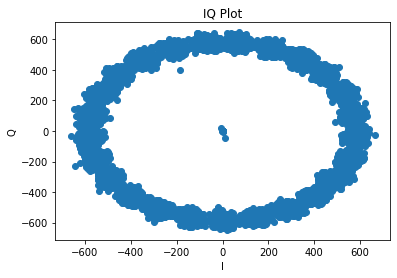

In [7]:
iq_plot(i_signal, q_signal)

In [8]:
# Sampling parameters
f = 5e6

# Create a time vector
N = i_signal.shape[0]
t_max = N/(f)
t = np.arange(0, t_max, 1/f)

# Tansform IQ data into a single signal
amplitude = np.sqrt(np.power(i_signal, 2) + np.power(q_signal, 2))
phi = np.arctan2(data[:,1], data[:,0])

# Received signal
rx_signal = amplitude*np.cos(2*np.pi*t*f + phi)

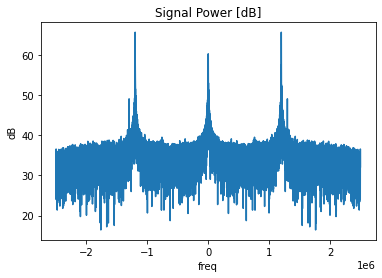

In [9]:
plot_power(rx_signal)

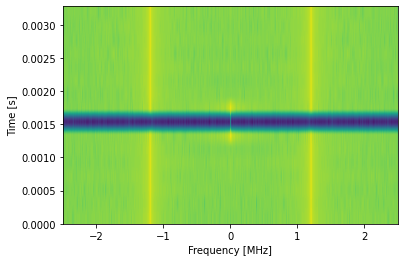

In [10]:
get_spectogram(rx_signal)

# Decimate Data

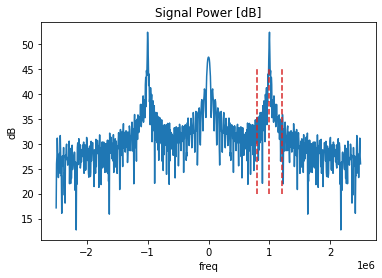

In [11]:
N = 20
rx_decimated = rx_signal[::N]
plot_power(rx_decimated)
# plt.vlines(x=1.80e6, ymin=20, ymax=45, linestyles="--", color="tab:red")
# plt.vlines(x=2.00e6, ymin=20, ymax=45, linestyles="--", color="tab:red")
# plt.vlines(x=2.20e6, ymin=20, ymax=45, linestyles="--", color="tab:red")
plt.vlines(x=0.80e6, ymin=20, ymax=45, linestyles="--", color="tab:red")
plt.vlines(x=1.00e6, ymin=20, ymax=45, linestyles="--", color="tab:red")
plt.vlines(x=1.20e6, ymin=20, ymax=45, linestyles="--", color="tab:red")

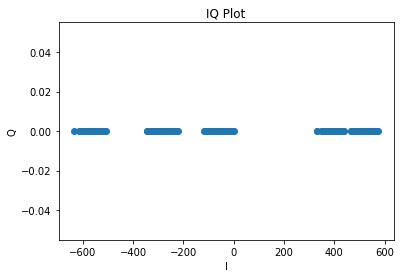

In [12]:
i_signal = np.real(rx_decimated)
q_signal = np.imag(rx_decimated)

iq_plot(i_signal, q_signal)

# Filter Data

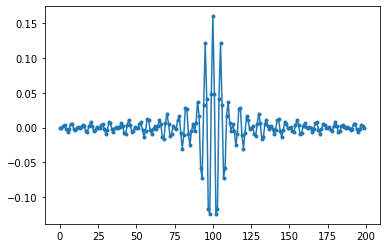

In [13]:
num_taps = 10001 # it helps to use an odd number of taps
cut_off = [0.80e6, 1.2e6] # Hz
# cut_off = [1.12e6, 1.28e6] # Hz
sample_rate = 5e6 # Hz

# create our low pass filter
h = signal.firwin(num_taps, cut_off, pass_zero="bandpass", nyq=sample_rate/2)

# plot the impulse response
plt.plot(h[4900:5100], '.-')
plt.show()

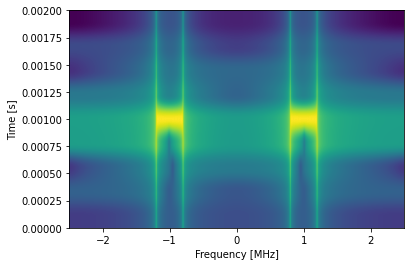

In [14]:
get_spectogram(h)

In [15]:
rx_filtered = np.convolve(rx_decimated, h)

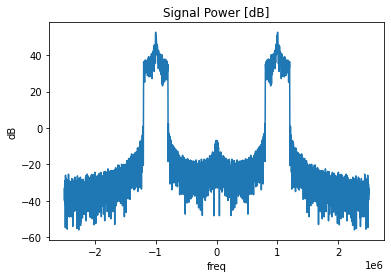

In [16]:
plot_power(rx_filtered)

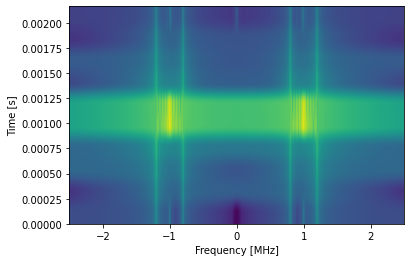

In [17]:
get_spectogram(rx_filtered)

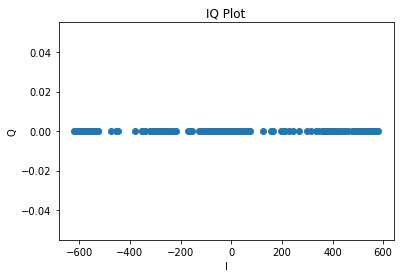

In [18]:
i_signal = np.real(rx_filtered)
q_signal = np.imag(rx_filtered)

iq_plot(i_signal, q_signal)

# Time Synchronization

In [19]:
x_time_sync = time_sync(rx_filtered)

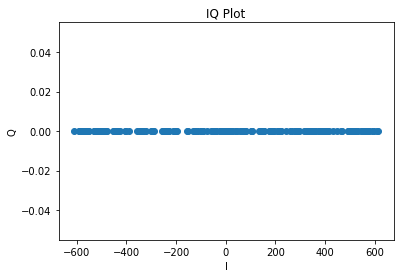

In [20]:
i_signal = np.real(x_time_sync)
q_signal = np.imag(x_time_sync)

iq_plot(i_signal, q_signal)

# Frequency Synchronization

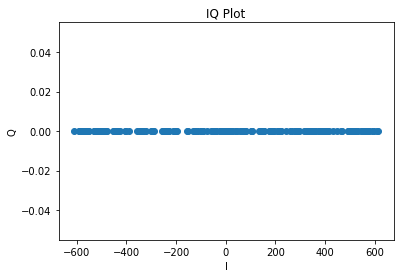

In [21]:
x_freq_sync, freq_log = fine_freq_sync(x_time_sync)

i_signal = np.real(x_freq_sync)
q_signal = np.imag(x_freq_sync)

iq_plot(i_signal, q_signal)